# Baseline GNN Prediction Visualization

This notebook loads a trained baseline graph neural network, runs inference on one GRaM sample, and compares **actual vs predicted** flow fields. It focuses on:

1. **Velocity contour comparisons**
2. **Pressure contour comparisons**
3. **Residual maps**
4. **Residual / convergence plots across the 5-step rollout**

> Set `CHECKPOINT_PATH` below to your trained baseline model checkpoint before running the inference cells.

In [24]:
from pathlib import Path
import importlib
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.tri import LinearTriInterpolator, Triangulation
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import torch
import yaml

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import src.datasets.gram_dataset as gram_dataset_module
import src.datasets.preprocessing as preprocessing_module
import src.datasets.splits as splits_module
import src.models as models_module

importlib.reload(gram_dataset_module)
importlib.reload(preprocessing_module)
importlib.reload(splits_module)
importlib.reload(models_module)

GRAMDataset = gram_dataset_module.GRAMDataset
scan_dataset_files = gram_dataset_module.scan_dataset_files
PhaseAPreprocessor = preprocessing_module.PhaseAPreprocessor
load_velocity_stats = preprocessing_module.load_velocity_stats
build_geometry_split = splits_module.build_geometry_split
summarize_split = splits_module.summarize_split
BaselineGNN = models_module.BaselineGNN
compute_knn = models_module.compute_knn

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
pd.set_option('display.max_columns', 40)
plt.style.use('seaborn-v0_8')
print(f'Using device: {DEVICE}')

Using device: cpu


In [25]:
CONFIG_PATH = ROOT / 'configs' / 'phase_a.yaml'
DEFAULT_CHECKPOINTS = [
    ROOT / 'outputs' / 'baseline_gnn' / 'best_model.pt',
    ROOT / 'outputs' / 'baseline_gnn' / 'best.pt',
    ROOT / 'outputs' / 'baseline_gnn.pt',
]

CHECKPOINT_PATH = next((path for path in DEFAULT_CHECKPOINTS if path.exists()), None)
PREDICTIONS_PATH = None  # optional: path to .npz or .pt with precomputed predictions
SPLIT_NAME = 'val'       # one of: 'train', 'val', 'test'
SAMPLE_INDEX = 0
FRAME_INDEX = -1         # -1 -> final forecast horizon
SLICE_AXIS = 2
ALLOW_RANDOM_FALLBACK = False

config = yaml.safe_load(CONFIG_PATH.read_text())
data_root = ROOT / config['data']['root']
records = scan_dataset_files(data_root)
split = build_geometry_split(
    records,
    val_fraction=float(config['split']['val_fraction']),
    seed=int(config['split']['seed']),
    num_test_simulations=int(config['split'].get('num_test_simulations', 0)),
    test_simulation_ids=config['split'].get('test_simulation_ids'),
)

datasets = {
    'train': GRAMDataset(data_root, records=split['train_records'], include_pressure=True),
    'val': GRAMDataset(data_root, records=split['val_records'], include_pressure=True),
    'test': GRAMDataset(data_root, records=split['test_records'], include_pressure=True),
}

velocity_stats = load_velocity_stats(ROOT / config['outputs']['velocity_stats'])
preprocessor = PhaseAPreprocessor(
    coordinate_mode=config['preprocessing']['coordinate_mode'],
    velocity_mean=velocity_stats['mean'],
    velocity_std=velocity_stats['std'],
    subsample_points=int(config['preprocessing']['subsample_points']),
    seed=int(config['split']['seed']),
    compute_boundary=bool(config['preprocessing'].get('compute_boundary_distance', True)),
    keep_airfoil=bool(config['preprocessing'].get('keep_airfoil', True)),
)

print(json.dumps(summarize_split(split), indent=2))
print(f'Checkpoint candidate: {CHECKPOINT_PATH}')
print(f'Split size for {SPLIT_NAME!r}: {len(datasets[SPLIT_NAME])}')

{
  "seed": 42,
  "val_fraction": 0.2,
  "num_train_records": 545,
  "num_val_records": 160,
  "num_test_records": 105,
  "num_train_simulations": 16,
  "num_val_simulations": 4,
  "num_test_simulations": 2,
  "overlap_simulation_ids": [],
  "overlap_train_val": [],
  "overlap_train_test": [],
  "overlap_val_test": []
}
Checkpoint candidate: /Users/ramtarun/Documents/my-projects/GRaM-PINO/outputs/baseline_gnn/best_model.pt
Split size for 'val': 160


In [26]:
def temporal_speed(velocity: np.ndarray) -> np.ndarray:
    return np.linalg.norm(velocity, axis=-1)


def denormalize_velocity(velocity: np.ndarray, mean: np.ndarray, std: np.ndarray) -> np.ndarray:
    mean = np.asarray(mean, dtype=np.float32).reshape(1, 1, 3)
    std = np.asarray(std, dtype=np.float32).reshape(1, 1, 3)
    return velocity * std + mean


def compute_focus_bounds(pos: np.ndarray, airfoil_mask: np.ndarray, pad_ratio: float = 0.35, min_pad: float = 0.02):
    pos = np.asarray(pos, dtype=np.float32)
    airfoil_mask = np.asarray(airfoil_mask, dtype=bool)
    airfoil_points = pos[airfoil_mask]

    if airfoil_points.size == 0:
        lo = pos.min(axis=0)
        hi = pos.max(axis=0)
    else:
        lo = airfoil_points.min(axis=0)
        hi = airfoil_points.max(axis=0)

    span = np.maximum(hi - lo, min_pad)
    pad = span * pad_ratio + min_pad
    return lo - pad, hi + pad


def sample_random_indices(indices: np.ndarray, max_points: int, seed: int = 0) -> np.ndarray:
    indices = np.asarray(indices, dtype=np.int64)
    if indices.size <= max_points:
        return np.sort(indices)
    rng = np.random.default_rng(seed)
    return np.sort(rng.choice(indices, size=max_points, replace=False).astype(np.int64))


def select_airfoil_slice(pos, values, airfoil_mask, axis=2, margin_ratio=0.35, width_scale=1.5, max_points=12000, seed=0):
    pos = np.asarray(pos, dtype=np.float32)
    values = np.asarray(values)
    airfoil_mask = np.asarray(airfoil_mask, dtype=bool)

    if axis == 0:
        axes_2d = (1, 2)
        labels = ('y', 'z')
    elif axis == 1:
        axes_2d = (0, 2)
        labels = ('x', 'z')
    else:
        axes_2d = (0, 1)
        labels = ('x', 'y')

    focus_lo, focus_hi = compute_focus_bounds(pos, airfoil_mask, pad_ratio=margin_ratio)
    in_box = (
        (pos[:, axes_2d[0]] >= focus_lo[axes_2d[0]])
        & (pos[:, axes_2d[0]] <= focus_hi[axes_2d[0]])
        & (pos[:, axes_2d[1]] >= focus_lo[axes_2d[1]])
        & (pos[:, axes_2d[1]] <= focus_hi[axes_2d[1]])
    )

    reference = pos[airfoil_mask, axis] if airfoil_mask.any() else pos[:, axis]
    center = float(np.median(reference))
    ref_span = float(np.ptp(reference)) if reference.size else float(np.ptp(pos[:, axis]))
    width = max(ref_span * width_scale + 0.01, 0.03)

    slice_mask = in_box & (np.abs(pos[:, axis] - center) <= width)
    if slice_mask.sum() < 300:
        width = max(width * 1.75, 0.05)
        slice_mask = in_box & (np.abs(pos[:, axis] - center) <= width)
    if slice_mask.sum() < 300:
        slice_mask = in_box

    idx = sample_random_indices(np.flatnonzero(slice_mask), max_points=max_points, seed=seed)
    coords_2d = pos[idx][:, axes_2d]
    return idx, coords_2d, values[idx], center, width, labels, airfoil_mask[idx]


def make_contour_grid(coords_2d: np.ndarray, vals: np.ndarray, grid_res: int = 220):
    x = coords_2d[:, 0]
    y = coords_2d[:, 1]
    tri = Triangulation(x, y)
    interpolator = LinearTriInterpolator(tri, vals)

    xi = np.linspace(float(x.min()), float(x.max()), grid_res)
    yi = np.linspace(float(y.min()), float(y.max()), grid_res)
    Xi, Yi = np.meshgrid(xi, yi)
    Zi = interpolator(Xi, Yi)
    Zi = np.ma.masked_invalid(Zi)
    return Xi, Yi, Zi, x, y, tri


def plot_scalar_panel(ax, pos, scalar, airfoil_mask, title, cmap='viridis', axis=2, seed=0, vmin=None, vmax=None, levels=40):
    idx, coords_2d, vals, center, width, labels, airfoil_slice = select_airfoil_slice(
        pos, scalar, airfoil_mask, axis=axis, seed=seed
    )
    Xi, Yi, Zi, x, y, tri = make_contour_grid(coords_2d, vals)

    artist = ax.contourf(Xi, Yi, Zi, levels=levels, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.contour(Xi, Yi, Zi, levels=max(10, levels // 4), colors='k', linewidths=0.25, alpha=0.2)

    if airfoil_slice.any():
        ax.scatter(x[airfoil_slice], y[airfoil_slice], s=6, c='#4C5A8A', alpha=0.95)

    plt.colorbar(artist, ax=ax, shrink=0.85)
    ax.set_title(f'{title}\nslice axis={axis}, center={center:.3f}, width={width:.3f}')
    ax.set_xlabel(labels[0])
    ax.set_ylabel(labels[1])
    ax.set_aspect('equal')
    ax.set_facecolor('#f7f7f7')


def plot_actual_pred_residual(axes, pos, actual, pred, airfoil_mask, title_prefix, cmap='viridis', residual_cmap='magma', axis=2, seed=0):
    residual = np.abs(pred - actual)
    common_min = float(np.nanmin([actual.min(), pred.min()]))
    common_max = float(np.nanmax([actual.max(), pred.max()]))

    plot_scalar_panel(
        axes[0], pos, actual, airfoil_mask, f'{title_prefix} — actual',
        cmap=cmap, axis=axis, seed=seed, vmin=common_min, vmax=common_max
    )
    plot_scalar_panel(
        axes[1], pos, pred, airfoil_mask, f'{title_prefix} — prediction',
        cmap=cmap, axis=axis, seed=seed, vmin=common_min, vmax=common_max
    )
    plot_scalar_panel(
        axes[2], pos, residual, airfoil_mask, f'{title_prefix} — |residual|',
        cmap=residual_cmap, axis=axis, seed=seed, vmin=0.0, vmax=float(residual.max())
    )


def make_interactive_graph_figure(pos, features, airfoil_mask, k_neighbors=6, max_nodes=220, seed=0):
    pos = np.asarray(pos, dtype=np.float32)
    features = np.asarray(features, dtype=np.float32)
    airfoil_mask = np.asarray(airfoil_mask, dtype=bool)

    node_idx = sample_random_indices(np.arange(pos.shape[0]), max_points=min(max_nodes, pos.shape[0]), seed=seed)
    sub_pos = pos[node_idx]
    sub_airfoil = airfoil_mask[node_idx]
    sub_features = features[node_idx]

    edge_index = compute_knn(
        torch.from_numpy(sub_pos).float().unsqueeze(0),
        k=k_neighbors,
    )[0].cpu().numpy()

    edge_x = []
    edge_y = []
    for src in range(edge_index.shape[0]):
        for dst in edge_index[src]:
            edge_x.extend([sub_pos[src, 0], sub_pos[dst, 0], None])
            edge_y.extend([sub_pos[src, 1], sub_pos[dst, 1], None])

    feature_strength = np.linalg.norm(sub_features[:, -3:], axis=1) if sub_features.shape[1] >= 3 else np.linalg.norm(sub_features, axis=1)
    hover_text = [
        f'node={i}<br>x={p[0]:.3f}<br>y={p[1]:.3f}<br>z={p[2]:.3f}<br>airfoil={bool(a)}<br>feature_norm={f:.3f}'
        for i, (p, a, f) in enumerate(zip(sub_pos, sub_airfoil, feature_strength))
    ]

    fig = go.Figure()
    fig.add_trace(
        go.Scatter(
            x=edge_x,
            y=edge_y,
            mode='lines',
            line=dict(width=0.6, color='rgba(120,120,120,0.5)'),
            hoverinfo='none',
            name='k-NN edges',
        )
    )
    fig.add_trace(
        go.Scatter(
            x=sub_pos[:, 0],
            y=sub_pos[:, 1],
            mode='markers',
            marker=dict(
                size=np.where(sub_airfoil, 7, 5),
                color=feature_strength,
                colorscale='Viridis',
                showscale=True,
                colorbar=dict(title='encoded\nfeature norm'),
                line=dict(width=0.5, color='black'),
            ),
            text=hover_text,
            hovertemplate='%{text}<extra></extra>',
            name='graph nodes',
        )
    )
    fig.update_layout(
        title='Interactive graph slice: nodes, edges, and encoded input strength',
        xaxis_title='x',
        yaxis_title='y',
        height=600,
        template='plotly_white',
    )
    fig.update_yaxes(scaleanchor='x', scaleratio=1)
    return fig


def make_interactive_input_feature_figure(pos, velocity_in, pressure, airfoil_mask, frame=0, max_points=5000, seed=0):
    pos = np.asarray(pos, dtype=np.float32)
    velocity_in = np.asarray(velocity_in, dtype=np.float32)
    pressure = None if pressure is None else np.asarray(pressure, dtype=np.float32)
    airfoil_mask = np.asarray(airfoil_mask, dtype=bool)

    idx = sample_random_indices(np.arange(pos.shape[0]), max_points=min(max_points, pos.shape[0]), seed=seed)
    speed = np.linalg.norm(velocity_in[frame], axis=-1)

    fig = go.Figure()
    fig.add_trace(
        go.Scatter3d(
            x=pos[idx, 0],
            y=pos[idx, 1],
            z=pos[idx, 2],
            mode='markers',
            marker=dict(
                size=2.8,
                color=speed[idx],
                colorscale='Turbo',
                opacity=0.78,
                colorbar=dict(title=f'|u| input t{frame - 4}'),
            ),
            text=[f'node={i}<br>speed={speed[i]:.3f}' for i in idx],
            hovertemplate='%{text}<extra></extra>',
            name='velocity encoding',
        )
    )

    airfoil_idx = idx[airfoil_mask[idx]]
    if airfoil_idx.size:
        fig.add_trace(
            go.Scatter3d(
                x=pos[airfoil_idx, 0],
                y=pos[airfoil_idx, 1],
                z=pos[airfoil_idx, 2],
                mode='markers',
                marker=dict(size=3.5, color='crimson'),
                name='airfoil points',
            )
        )

    if pressure is not None:
        fig.add_trace(
            go.Scatter3d(
                x=pos[idx, 0],
                y=pos[idx, 1],
                z=pos[idx, 2],
                mode='markers',
                visible=False,
                marker=dict(
                    size=2.8,
                    color=pressure[frame][idx],
                    colorscale='RdBu_r',
                    opacity=0.78,
                    colorbar=dict(title=f'pressure t{frame - 4}'),
                ),
                text=[f'node={i}<br>pressure={pressure[frame][i]:.3f}' for i in idx],
                hovertemplate='%{text}<extra></extra>',
                name='pressure encoding',
            )
        )

    buttons = [
        dict(
            label='Velocity encoding',
            method='update',
            args=[{'visible': [True, airfoil_idx.size > 0] + ([False] if pressure is not None else [])},
                  {'title': 'Interactive 3D view of input velocity encoding'}],
        )
    ]
    if pressure is not None:
        buttons.append(
            dict(
                label='Pressure encoding',
                method='update',
                args=[{'visible': [False, airfoil_idx.size > 0, True]},
                      {'title': 'Interactive 3D view of input pressure encoding'}],
            )
        )

    fig.update_layout(
        title='Interactive 3D view of input velocity encoding',
        height=700,
        template='plotly_white',
        updatemenus=[dict(type='buttons', direction='right', buttons=buttons, x=0.0, y=1.12)],
        scene=dict(aspectmode='data', xaxis_title='x', yaxis_title='y', zaxis_title='z'),
    )
    return fig


def _extract_state_dict(checkpoint):
    if isinstance(checkpoint, dict):
        for key in ('model_state_dict', 'state_dict', 'model_state'):
            if key in checkpoint:
                return checkpoint[key], checkpoint.get('model_config', {})
    return checkpoint, {}


def build_model_from_checkpoint(checkpoint_path: Path, in_dim: int) -> BaselineGNN:
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    state_dict, model_config = _extract_state_dict(checkpoint)

    output_steps = int(model_config.get('output_steps', 5))
    predict_pressure = model_config.get('predict_pressure')
    decoder_weight = state_dict.get('decoder.2.weight')
    if predict_pressure is None and decoder_weight is not None:
        per_step = decoder_weight.shape[0] // output_steps
        predict_pressure = per_step == 4
    predict_pressure = True if predict_pressure is None else bool(predict_pressure)

    model = BaselineGNN(
        in_dim=in_dim,
        hidden_dim=int(model_config.get('hidden_dim', 128)),
        num_layers=int(model_config.get('num_layers', 4)),
        k_neighbors=int(model_config.get('k_neighbors', 12)),
        output_steps=output_steps,
        predict_pressure=predict_pressure,
    ).to(DEVICE)

    missing, unexpected = model.load_state_dict(state_dict, strict=False)
    if missing:
        print('Missing keys:', missing)
    if unexpected:
        print('Unexpected keys:', unexpected)
    model.eval()
    return model


def load_prediction_bundle(raw_sample, checkpoint_path=None, predictions_path=None):
    processed = preprocessor(raw_sample)
    actual_velocity = np.asarray(processed['velocity_out'], dtype=np.float32)

    pressure = processed.get('pressure')
    actual_pressure = None
    if pressure is not None:
        pressure = np.asarray(pressure, dtype=np.float32)
        actual_pressure = pressure[5:] if pressure.shape[0] >= 10 else pressure[-5:]

    pred_velocity = None
    pred_pressure = None

    if predictions_path is not None:
        predictions_path = Path(predictions_path)
        if predictions_path.suffix == '.npz':
            payload = np.load(predictions_path)
            pred_velocity = np.asarray(payload['pred_velocity'], dtype=np.float32)
            if 'pred_pressure' in payload:
                pred_pressure = np.asarray(payload['pred_pressure'], dtype=np.float32)
        else:
            payload = torch.load(predictions_path, map_location='cpu')
            pred_velocity = np.asarray(payload['pred_velocity'], dtype=np.float32)
            if 'pred_pressure' in payload:
                pred_pressure = np.asarray(payload['pred_pressure'], dtype=np.float32)
    elif checkpoint_path is not None:
        input_features = torch.from_numpy(processed['input_features']).float().unsqueeze(0).to(DEVICE)
        pos = torch.from_numpy(processed['pos']).float().unsqueeze(0).to(DEVICE)
        model = build_model_from_checkpoint(Path(checkpoint_path), in_dim=processed['input_features'].shape[-1])

        with torch.no_grad():
            outputs = model(input_features, pos)

        pred_velocity = outputs['velocity'][0].detach().cpu().numpy()
        if 'pressure' in outputs:
            pred_pressure = outputs['pressure'][0].detach().cpu().numpy()
    elif ALLOW_RANDOM_FALLBACK:
        print('Warning: checkpoint not found. Using a randomly initialized BaselineGNN.')
        input_features = torch.from_numpy(processed['input_features']).float().unsqueeze(0).to(DEVICE)
        pos = torch.from_numpy(processed['pos']).float().unsqueeze(0).to(DEVICE)
        model = BaselineGNN(in_dim=processed['input_features'].shape[-1]).to(DEVICE).eval()
        with torch.no_grad():
            outputs = model(input_features, pos)
        pred_velocity = outputs['velocity'][0].detach().cpu().numpy()
        if 'pressure' in outputs:
            pred_pressure = outputs['pressure'][0].detach().cpu().numpy()
    else:
        print('No prediction source found yet. Set CHECKPOINT_PATH or PREDICTIONS_PATH to compare actual vs predicted fields.')

    if 'velocity_stats' in processed:
        stats = processed['velocity_stats']
        actual_velocity = denormalize_velocity(actual_velocity, stats['mean'], stats['std'])
        if pred_velocity is not None:
            pred_velocity = denormalize_velocity(pred_velocity, stats['mean'], stats['std'])

    return processed, actual_velocity, pred_velocity, actual_pressure, pred_pressure


def find_training_history(root: Path):
    candidates = [
        root / 'outputs' / 'baseline_gnn' / 'history.json',
        root / 'outputs' / 'baseline_gnn' / 'metrics.json',
        root / 'outputs' / 'training_history.json',
    ]
    for path in candidates:
        if path.exists():
            return path
    return None

In [27]:
raw_sample = datasets[SPLIT_NAME][SAMPLE_INDEX]
processed_sample, actual_velocity, pred_velocity, actual_pressure, pred_pressure = load_prediction_bundle(
    raw_sample,
    checkpoint_path=CHECKPOINT_PATH,
    predictions_path=PREDICTIONS_PATH,
)

frame_idx = FRAME_INDEX if FRAME_INDEX >= 0 else actual_velocity.shape[0] + FRAME_INDEX
metadata = processed_sample['metadata']

print(json.dumps(metadata, indent=2))
print(f'Visualising split={SPLIT_NAME}, sample_index={SAMPLE_INDEX}, frame=t+{frame_idx + 1}')

if pred_velocity is None:
    metrics = None
    print('Predictions are not loaded yet. Update CHECKPOINT_PATH or PREDICTIONS_PATH, then rerun this cell.')
else:
    speed_actual = temporal_speed(actual_velocity)
    speed_pred = temporal_speed(pred_velocity)

    reduction_axes = tuple(range(1, actual_velocity.ndim))
    velocity_rmse = np.sqrt(np.mean((pred_velocity - actual_velocity) ** 2, axis=reduction_axes))
    velocity_mae = np.mean(np.abs(pred_velocity - actual_velocity), axis=reduction_axes)
    metrics = pd.DataFrame({
        'horizon': np.arange(1, actual_velocity.shape[0] + 1),
        'velocity_mae': velocity_mae,
        'velocity_rmse': velocity_rmse,
    })

    if actual_pressure is not None and pred_pressure is not None:
        metrics['pressure_mae'] = np.mean(np.abs(pred_pressure - actual_pressure), axis=1)
        metrics['pressure_rmse'] = np.sqrt(np.mean((pred_pressure - actual_pressure) ** 2, axis=1))

    display(metrics)

{
  "file_path": "/Users/ramtarun/Documents/my-projects/GRaM-PINO/warped-ifw/1023_1-0.npz",
  "file_name": "1023_1-0.npz",
  "simulation_id": 1023,
  "window_id": 1,
  "variant_id": 0,
  "num_points": 4096,
  "num_airfoil_points": 754,
  "num_points_before_subsample": 100000,
  "subsample_seed": 42
}
Visualising split=val, sample_index=0, frame=t+5


,horizon,velocity_mae,velocity_rmse,pressure_mae,pressure_rmse
0,1,2.038145,4.294944,277.751251,485.088165
1,2,2.461335,5.107302,280.105530,491.607056
2,3,2.042321,4.493727,279.850342,491.250671
3,4,2.148487,4.601413,278.370911,485.400909
4,5,2.071641,4.455960,278.078430,484.614075


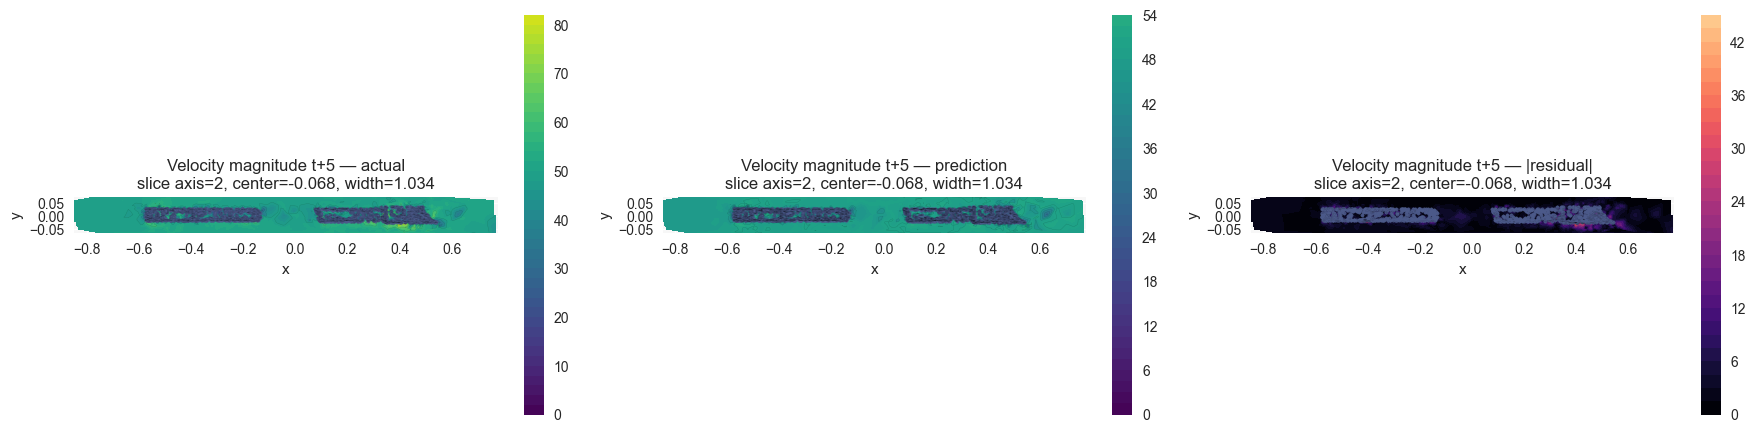

In [28]:
if pred_velocity is None:
    print('Load a trained checkpoint first to render velocity prediction contours.')
else:
    speed_actual = temporal_speed(actual_velocity)
    speed_pred = temporal_speed(pred_velocity)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    plot_actual_pred_residual(
        axes,
        processed_sample['pos'],
        speed_actual[frame_idx],
        speed_pred[frame_idx],
        processed_sample['airfoil_mask'],
        title_prefix=f'Velocity magnitude t+{frame_idx + 1}',
        cmap='viridis',
        residual_cmap='magma',
        axis=SLICE_AXIS,
        seed=frame_idx,
    )
    plt.tight_layout()
    plt.show()

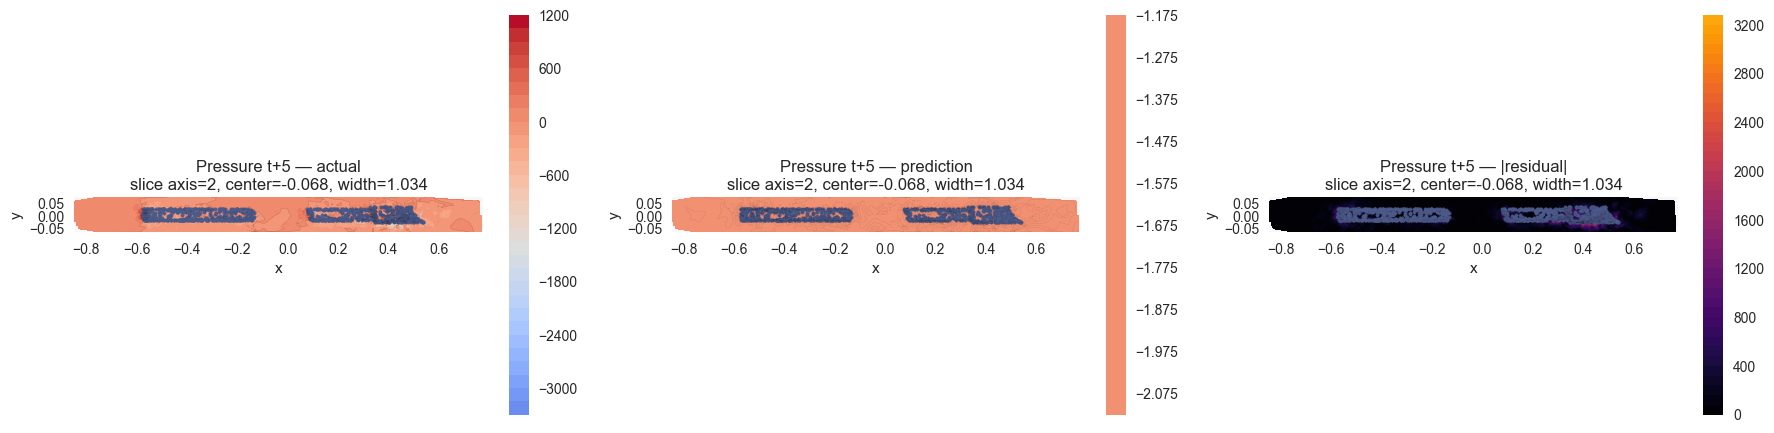

In [29]:
if actual_pressure is None:
    print('Pressure is not available in this sample.')
elif pred_pressure is None:
    print('The loaded baseline output does not include pressure predictions yet. Use a checkpoint with predict_pressure=True to compare pressure contours.')
else:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    plot_actual_pred_residual(
        axes,
        processed_sample['pos'],
        actual_pressure[frame_idx],
        pred_pressure[frame_idx],
        processed_sample['airfoil_mask'],
        title_prefix=f'Pressure t+{frame_idx + 1}',
        cmap='coolwarm',
        residual_cmap='inferno',
        axis=SLICE_AXIS,
        seed=frame_idx,
    )
    plt.tight_layout()
    plt.show()

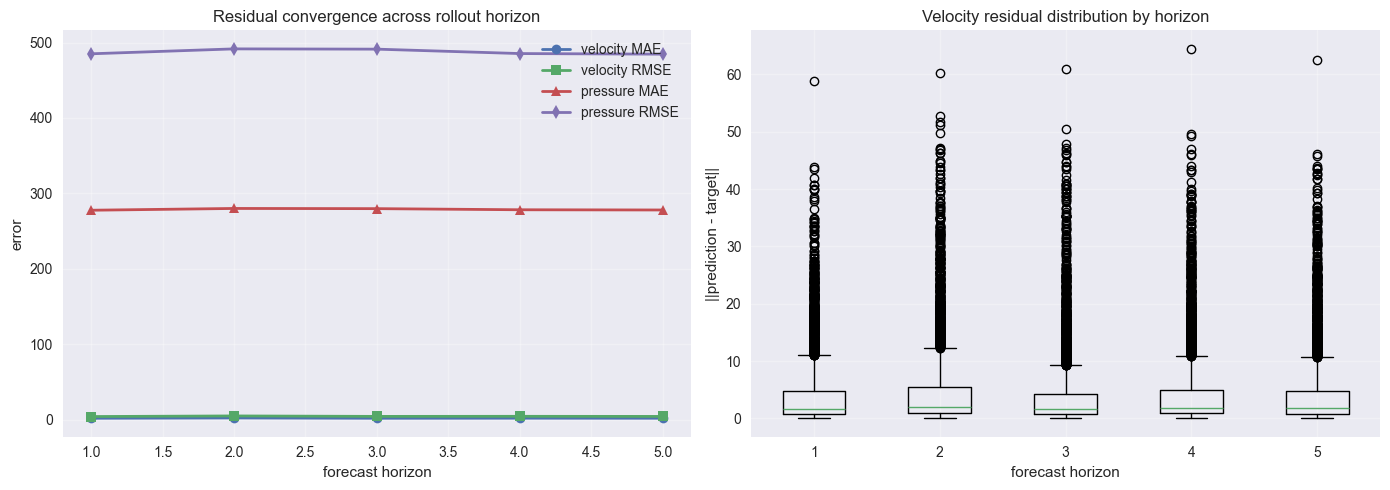

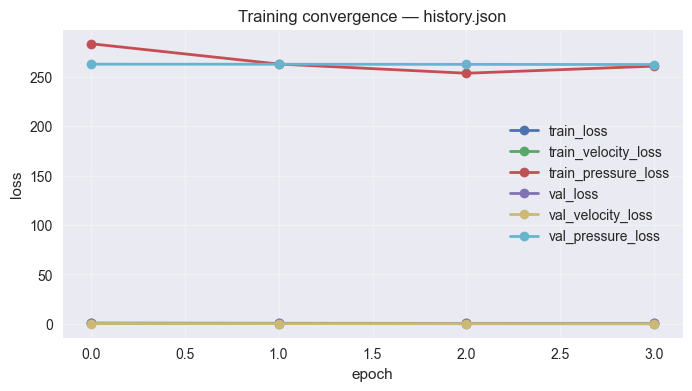

In [30]:
if metrics is None:
    print('Residual convergence plots will appear after loading baseline predictions.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(metrics['horizon'], metrics['velocity_mae'], marker='o', linewidth=2, label='velocity MAE')
    axes[0].plot(metrics['horizon'], metrics['velocity_rmse'], marker='s', linewidth=2, label='velocity RMSE')
    if 'pressure_mae' in metrics:
        axes[0].plot(metrics['horizon'], metrics['pressure_mae'], marker='^', linewidth=2, label='pressure MAE')
        axes[0].plot(metrics['horizon'], metrics['pressure_rmse'], marker='d', linewidth=2, label='pressure RMSE')
    axes[0].set_title('Residual convergence across rollout horizon')
    axes[0].set_xlabel('forecast horizon')
    axes[0].set_ylabel('error')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    velocity_residual = np.linalg.norm(pred_velocity - actual_velocity, axis=-1)
    axes[1].boxplot(
        [velocity_residual[h].ravel() for h in range(velocity_residual.shape[0])],
        tick_labels=metrics['horizon'],
    )
    axes[1].set_title('Velocity residual distribution by horizon')
    axes[1].set_xlabel('forecast horizon')
    axes[1].set_ylabel('||prediction - target||')
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

history_path = find_training_history(ROOT)
if history_path is not None:
    history = json.loads(history_path.read_text())
    history_df = pd.DataFrame(history)
    loss_columns = [col for col in history_df.columns if 'loss' in col.lower()]
    if loss_columns:
        history_df[loss_columns].plot(figsize=(8, 4), marker='o', linewidth=2, title=f'Training convergence — {history_path.name}')
        plt.xlabel('epoch')
        plt.ylabel('loss')
        plt.grid(alpha=0.3)
        plt.show()
else:
    print('No training-history JSON found under outputs/. Add one to also visualise epoch-wise convergence.')

## Interactive graph and feature encoding views

The next cells provide interactive views of the induced graph structure and show how the input velocity and pressure fields are encoded on the sampled graph nodes.

In [31]:
interactive_graph = make_interactive_graph_figure(
    processed_sample['pos'],
    processed_sample['input_features'],
    processed_sample['airfoil_mask'],
    k_neighbors=6,
    max_nodes=220,
    seed=int(frame_idx),
)
interactive_graph

In [32]:
interactive_encoding = make_interactive_input_feature_figure(
    processed_sample['pos'],
    processed_sample['velocity_in'],
    processed_sample.get('pressure'),
    processed_sample['airfoil_mask'],
    frame=4,
    max_points=5000,
    seed=int(frame_idx),
)
interactive_encoding